# Hyperspectral Detection of *Orobanche minor* Parasitism in Red Clover
## Analysis code for: "Hyperspectral sensing to identify *Orobanche minor* parasitism in red clover"

This notebook contains the complete analysis used in the manuscript. Running
all cells from top to bottom reproduces every table and figure.

### Data
Four datasets of leaf reflectance spectra (ASD FieldSpec 4, 350–2500 nm),
each with parasitized and non-parasitized red clover plants:

| Dataset | File | Parasitized | Non-parasitized |
|---|---|---|---|
| 2024 Greenhouse | `2024 GH.xlsx` | 12 | 12 |
| 2024 Field | `2024 Field.xlsx` | 12 | 12 |
| 2025 Greenhouse | `2025 GH.xlsx` | 23 | 23 |
| 2025 Field | `2025 Field.xlsx` | 10 | 10 |

The data are available at https://doi.org/10.17632/4kmm7j3kfz.1.
Place the four files in the same folder as this notebook before running it.

### Analysis workflow
1. **Pre-processing:** removal of noisy spectral regions, then a first
   derivative computed as a simple finite difference between adjacent 1-nm
   bands. No smoothing (e.g., Savitzky–Golay) or scatter correction (e.g., SNV)
   is applied.
2. **PLS-DA models:** partial least squares regression with classes coded
   0 = non-parasitized and 1 = parasitized, and predictions ≥ 0.5 classified
   as parasitized. Models are fit separately to raw and first-derivative spectra.
3. **Model validation:**
   - *Nested leave-one-out cross-validation* within each dataset. The number
     of PLS components (1–10) is chosen using only the training plants in
     each fold.
   - *Cross-year validation:* a model trained on one year is tested on the
     other year from the same environment.
4. **Wavelength importance:** Variable Importance in Projection (VIP) scores,
   wavelengths with VIP>1 in all four datasets, a reduced
   model using only the selected wavelengths.

### Output
All figures and tables are saved to the folder set by `OUTPUT_DIR` in Section 2.

## Section 1 — Imports

Python libraries used in the analysis. The versions printed at the end of the
next cell are the versions used to produce the results in the manuscript.

- **numpy, pandas:** data handling
- **matplotlib:** figures
- **scikit-learn:** PLS models (`PLSRegression`), leave-one-out
  cross-validation (`LeaveOneOut`, `cross_val_predict`), and performance
  metrics

In [1]:
# Data handling
import os
import numpy as np
import pandas as pd

# Figures
import matplotlib.pyplot as plt

# PLS model and cross-validation
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict

# Performance metrics
#   mean_squared_error : RMSEC / RMSEP (regression-style error)
#   the others         : classification metrics computed from the
#                        cross-validated predictions (accuracy, sensitivity,
#                        specificity, precision, F1 score, ROC-AUC)
from sklearn.metrics import (mean_squared_error, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

# Suppress library warnings (e.g., future-version notices) to keep the output readable
import warnings
warnings.filterwarnings('ignore')

# Library versions used to produce the results in the manuscript
import sys, sklearn, scipy, matplotlib, openpyxl
print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__)
print("matplotlib  ", matplotlib.__version__)
print("openpyxl    ", openpyxl.__version__)

Python       3.11.15
numpy        2.4.6
pandas       3.0.3
scikit-learn 1.9.0
scipy        1.17.1
matplotlib   3.11.0
openpyxl     3.1.5


## Section 2 — Configuration

All settings used in the analysis are defined here, so they can be checked or
changed in one place:

- **Datasets:** the four data files and their year and environment
- **Display order:** the order of datasets in tables and figures
- **Noisy regions removed:** spectral ranges excluded before analysis
  (sensor noise at the edges of the instrument range and strong
  water-absorption regions). 1,641 of 2,151 bands (400–2396 nm) remain.
- **Spectral regions:** the names used to label wavelengths (VIS, red edge,
  NIR, SWIR-1, SWIR-2)
- **Maximum number of PLS components** tested during model selection (10)
- **Output folder** for all figures and tables

In [2]:
# ---------------------------------------------------------------------------
# Datasets: file name, year and environment for each dataset.
# Each file contains one row per plant: sample_id, treatment
# ('healthy' / 'parasitized'), treatment_code (0 = non-parasitized,
# 1 = parasitized), and one column per wavelength (350-2500 nm, 1-nm steps).
# ---------------------------------------------------------------------------
DATASETS = [
    {"filepath": "2024 GH.xlsx",  "year": "2024", "location": "Greenhouse"},
    {"filepath": "2024 Field.xlsx",  "year": "2024", "location": "Field"},
    {"filepath": "2025 GH.xlsx",  "year": "2025", "location": "Greenhouse"},
    {"filepath": "2025 Field.xlsx",  "year": "2025", "location": "Field"},
]

# ---------------------------------------------------------------------------
# Display order
# ---------------------------------------------------------------------------
# Order of datasets in Table 3 and the VIP tables
PANEL_ORDER = [("2024", "Greenhouse"), ("2024", "Field"),
               ("2025", "Greenhouse"), ("2025", "Field")]

# Order of panels in the 2x2 figures (Figures 1-3):
# greenhouse on top, field on bottom
# (a) 2024 GH, (b) 2025 GH, (c) 2024 Field, (d) 2025 Field
FIG_PANEL_ORDER = [("2024", "Greenhouse"), ("2025", "Greenhouse"),
                   ("2024", "Field"), ("2025", "Field")]
PANEL_LETTERS = ["(a)", "(b)", "(c)", "(d)"]

# ---------------------------------------------------------------------------
# Noisy spectral regions removed before analysis (Apan et al., 2005).
# Both ends of each range are removed. After removal, 1,641 bands remain
# (400-1355, 1481-1790 and 2022-2396 nm).
# ---------------------------------------------------------------------------
NOISY_RANGES = [
    (350, 399),     # low-signal edge of the instrument range
    (1356, 1480),   # water absorption
    (1791, 2021),   # water absorption
    (2397, 2500),   # low-signal edge of the instrument range
]

# ---------------------------------------------------------------------------
# Named spectral regions, used to label wavelengths in the VIP tables.
# Each range includes the lower value and excludes the upper value, e.g.
# VIS = 400-699 nm, Red-edge = 700-729 nm (as defined in the manuscript).
# ---------------------------------------------------------------------------
SPECTRAL_REGIONS = [
    (400, 700, 'VIS'),
    (700, 730, 'Red-edge'),
    (730, 1300, 'NIR'),
    (1300, 1800, 'SWIR-1'),
    (1800, 2500, 'SWIR-2'),
]

# ---------------------------------------------------------------------------
# PLS model selection: 1 to MAX_COMPONENTS components are tested, and the
# smallest number with the lowest leave-one-out RMSECV is chosen.
# ---------------------------------------------------------------------------
MAX_COMPONENTS = 10

# ---------------------------------------------------------------------------
# Output folder: all figures and tables are saved here.
# ---------------------------------------------------------------------------
OUTPUT_DIR = "Results_nested_CV"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Section 3 — Helper Functions

The functions used in the analysis are defined in this section, each in its own
cell, grouped by analysis step:

- **3a. Pre-processing:** removal of noisy bands; first derivative
- **3b. Spectral region labels**
- **3c. PLS-DA model:** selection of the number of components, nested
  leave-one-out cross-validation, final model
- **3d. Classification metrics:** accuracy, sensitivity, specificity,
  precision, F1 score, ROC-AUC
- **3e. VIP scores**
- **3f. Grouping selected wavelengths into contiguous bands**

These cells only define functions. They are run on the data in Section 4.

### 3a. Pre-processing

1. **Noisy-band removal:** wavelengths in the ranges listed in `NOISY_RANGES`
   (Section 2) are removed.
2. **First derivative:** the difference in reflectance between each pair of
   adjacent 1-nm bands. No smoothing is applied. Each derivative value is
   labeled with the wavelength of the lower band of the pair (e.g., the value
   labeled 713 nm is reflectance at 714 nm minus reflectance at 713 nm).
   Differences across a removed region (e.g., 1355 → 1481 nm) are not
   calculated, because those bands are not adjacent.

In [3]:
def remove_noisy_bands(wavelengths, noisy_ranges):
    """
    Return a True/False mask for the wavelengths to KEEP.

    A wavelength is removed (False) if it falls inside any of the ranges in
    noisy_ranges (both ends included). All other wavelengths are kept (True).
    """
    mask = np.ones(len(wavelengths), dtype=bool)
    for lo, hi in noisy_ranges:
        mask &= ~((wavelengths >= lo) & (wavelengths <= hi))
    return mask

In [4]:
def compute_first_derivative(X, wavelengths):
    """
    First derivative by finite differencing between adjacent bands (no smoothing).

    For each plant, the derivative at band i is: reflectance[i+1] - reflectance[i].
    Each value is labeled with the wavelength of the LOWER band (band i).

    Differences between bands that are not adjacent (i.e., across a removed
    noisy region, where the wavelength step is larger than 1 nm) are dropped.

    Returns
    -------
    X_deriv  : first-derivative spectra (plants x derivative bands)
    wl_deriv : wavelength label for each derivative band
    """
    X_deriv = np.diff(X, axis=1)
    wl_left = wavelengths[:-1]
    wl_right = wavelengths[1:]
    is_adjacent = (wl_right - wl_left) <= 1.5   # adjacent bands are 1 nm apart
    return X_deriv[:, is_adjacent], wl_left[is_adjacent]

### 3b. Spectral region labels

Returns the name of the spectral region (VIS, Red-edge, NIR, SWIR-1, SWIR-2)
for a wavelength, using the ranges defined in `SPECTRAL_REGIONS` (Section 2).
Used to label wavelengths in the VIP tables.

In [5]:
def spectral_region_name(wavelength):
    """
    Return the spectral region name for a wavelength (nm), using the ranges
    in SPECTRAL_REGIONS (lower value included, upper value excluded).
    """
    for lo, hi, name in SPECTRAL_REGIONS:
        if lo <= wavelength < hi:
            return name
    return 'Outside named regions'

### 3c. PLS-DA model: component selection and nested cross-validation

**Model.** Partial least squares discriminant analysis (PLS-DA): PLS regression
with the two classes coded as 0 (non-parasitized) and 1 (parasitized). A plant
is classified as parasitized if its predicted value is ≥ 0.5. Each wavelength is
mean-centered and scaled to unit variance inside the model (`scale=True`).

**Choosing the number of components** (`select_n_components_loo`). Models with
1 to 10 components are each evaluated by leave-one-out cross-validation (LOO).
The number chosen is the smallest one with the lowest cross-validated error
(RMSECV).

**Nested leave-one-out cross-validation** (`nested_loo_predictions`). This is
used to estimate how well the model predicts plants it has not seen:

1. **Outer loop:** one plant is held out as the test plant.
2. **Inner loop:** using only the remaining plants, the number of components
   is chosen with `select_n_components_loo`.
3. A model with that number of components is fit to the remaining plants and
   used to predict the held-out plant.
4. Steps 1–3 are repeated until every plant has been held out once.

Because the held-out plant is never used to choose the number of components,
the predictions are not biased by model selection. The number of components
can differ between outer folds; the range is reported in Table 3.

**Final model and summary** (`fit_pls_with_nested_cv`).
- *Cross-validated performance* (R cv, RMSEP, accuracy and the classification
  metrics in 3d) comes from the nested predictions.
- *The final model* is fit to all plants, with the number of components chosen
  by `select_n_components_loo` on all plants. This model is used for the
  calibration statistics (R cal, RMSEC), the score plots (Figure 3) and the
  VIP scores.

In [6]:
def select_n_components_loo(X, y, max_components=10):
    """
    Select the number of PLS components by leave-one-out cross-validation:
    the smallest number of components at which the LOO RMSECV reaches its
    minimum. Uses only the X, y passed in.
    """
    loo = LeaveOneOut()
    best_rmsecv = np.inf
    best_n_comp = 1
    n_comp_limit = min(max_components, X.shape[0] - 1, X.shape[1])

    for n in range(1, n_comp_limit + 1):
        pls_trial = PLSRegression(n_components=n, scale=True)
        y_oof = cross_val_predict(pls_trial, X, y, cv=loo)
        rmsecv = np.sqrt(mean_squared_error(y, y_oof))
        if rmsecv < best_rmsecv:
            best_rmsecv = rmsecv
            best_n_comp = n

    return best_n_comp

In [7]:
def nested_loo_predictions(X, y, max_components=10):
    """
    Nested leave-one-out cross-validation.

    Outer loop : each plant is held out once as the test plant.
    Inner loop : the number of components is chosen by LOO on the remaining
                 plants only (select_n_components_loo).
    A model with that number of components is fit to the remaining plants and
    used to predict the held-out plant.

    Returns
    -------
    y_outer_pred : one cross-validated prediction per plant
    outer_n_comp : number of components chosen in each outer fold
    """
    n = X.shape[0]
    y_outer_pred = np.zeros(n)
    outer_n_comp = np.zeros(n, dtype=int)

    for i in range(n):
        # Outer loop: hold out plant i
        train = np.arange(n) != i
        X_train, y_train = X[train], y[train]

        # Inner loop: choose the number of components from the training plants only
        n_comp = select_n_components_loo(X_train, y_train, max_components)

        # Fit on the training plants and predict the held-out plant
        model = PLSRegression(n_components=n_comp, scale=True)
        model.fit(X_train, y_train)
        y_outer_pred[i] = model.predict(X[[i]]).ravel()[0]
        outer_n_comp[i] = n_comp

    return y_outer_pred, outer_n_comp

In [8]:
def fit_pls_with_nested_cv(X, y, max_components=10):
    """
    Fit the final PLS-DA model and summarize its performance.

    Calibration statistics : from the final model fit to ALL plants
                             (number of components chosen by LOO on all plants).
    Cross-validated statistics : from the nested LOO predictions
                                 (nested_loo_predictions), i.e. each plant
                                 predicted by a model that never saw it.

    Returns
    -------
    pls_model  : final model fit to all plants (used for score plots and VIP)
    metrics    : dictionary of performance statistics
    y_cal_pred : calibration predictions (final model, all plants)
    y_cv_pred  : nested cross-validated predictions
    """
    # --- Final model on all plants ---
    best_n_comp = select_n_components_loo(X, y, max_components)
    pls_model = PLSRegression(n_components=best_n_comp, scale=True)
    pls_model.fit(X, y)

    # --- Calibration performance (final model) ---
    y_cal_pred = pls_model.predict(X).ravel()
    rmsec = np.sqrt(mean_squared_error(y, y_cal_pred))
    r_cal = np.corrcoef(y, y_cal_pred)[0, 1]

    # --- Cross-validated performance (nested LOO) ---
    y_cv_pred, outer_n_comp = nested_loo_predictions(X, y, max_components)
    rmsep = np.sqrt(mean_squared_error(y, y_cv_pred))
    r_cv = np.corrcoef(y, y_cv_pred)[0, 1]

    # Classification accuracy: prediction >= 0.5 -> parasitized (1), otherwise non-parasitized (0)
    y_true_bin = (y >= 0.5).astype(int)
    y_pred_bin = (y_cv_pred >= 0.5).astype(int)
    accuracy = np.mean(y_true_bin == y_pred_bin) * 100.0

    metrics = {
        "n_components": best_n_comp,                       # final model
        "outer_n_comp_min": int(outer_n_comp.min()),       # range across outer folds
        "outer_n_comp_max": int(outer_n_comp.max()),
        "r_cal": r_cal, "rmsec": rmsec,                    # calibration
        "r_cv": r_cv, "rmsep": rmsep,                      # nested cross-validation
        "accuracy": accuracy,
    }
    return pls_model, metrics, y_cal_pred, y_cv_pred

### 3d. Classification performance metrics

Distinguishing parasitized from non-parasitized plants is a two-class
problem, so in addition to the regression-style statistics in 3c (R, RMSEC,
RMSEP), standard classification metrics are calculated (as in Atsmon et al.,
2022). All are computed from the **nested cross-validated predictions**
produced by `fit_pls_with_nested_cv`, using the same 0.5 cutoff:

| Metric | Meaning |
|---|---|
| Accuracy | % of all plants classified correctly |
| Sensitivity | proportion of parasitized plants correctly classified as parasitized |
| Specificity | proportion of non-parasitized plants correctly classified as non-parasitized |
| Precision | proportion of plants classified as parasitized that were truly parasitized |
| F1 score | harmonic mean of precision and sensitivity |
| ROC-AUC | ability to rank parasitized above non-parasitized plants across all possible cutoffs (not only 0.5) |

**Built-in check:** accuracy is calculated a second time here, independently,
and compared with the accuracy from `fit_pls_with_nested_cv` in Section 4.
The two must match exactly. If they don't, the analysis stops with an error.

In [9]:
def compute_classification_metrics(y_true, y_pred_continuous, threshold=0.5):
    """
    Classification metrics from continuous PLS-DA predictions.

    Predictions >= threshold are classified as parasitized (1); all others as
    non-parasitized (0).

    Parameters
    ----------
    y_true            : true classes (0 = non-parasitized, 1 = parasitized)
    y_pred_continuous : continuous PLS-DA predictions (e.g., nested CV predictions)
    threshold         : classification cutoff (default 0.5)

    Returns
    -------
    dict with accuracy_check, sensitivity, specificity, precision, f1_score,
    roc_auc, and the confusion-matrix counts (tp, tn, fp, fn).
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred_class = (np.asarray(y_pred_continuous) >= threshold).astype(int)

    # Confusion-matrix counts (labels=[0, 1] fixes the order: tn, fp, fn, tp)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_class, labels=[0, 1]).ravel()

    # Accuracy, recalculated independently as a check against the accuracy
    # from fit_pls_with_nested_cv (the two must match; see Section 4)
    accuracy_check = accuracy_score(y_true, y_pred_class) * 100.0

    # Sensitivity (recall): TP / (TP + FN)
    sensitivity = recall_score(y_true, y_pred_class, pos_label=1, zero_division=0)

    # Specificity: TN / (TN + FP)  (no built-in scikit-learn function)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    # Precision: TP / (TP + FP)
    precision = precision_score(y_true, y_pred_class, pos_label=1, zero_division=0)

    # F1 score: harmonic mean of precision and sensitivity
    f1 = f1_score(y_true, y_pred_class, pos_label=1, zero_division=0)

    # ROC-AUC: uses the continuous predictions (no cutoff applied)
    roc_auc = roc_auc_score(y_true, y_pred_continuous)

    return {
        "accuracy_check": accuracy_check,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1_score": f1,
        "roc_auc": roc_auc,
        "tp": int(tp), "tn": int(tn), "fp": int(fp), "fn": int(fn),
    }

In [10]:
from scipy.stats import binomtest

def exact_ci(k, n, conf=0.95):
    """
    Exact binomial (Clopper-Pearson) confidence interval for a proportion k/n.
    Returns (lower, upper) as proportions (0-1).
    """
    if n == 0:
        return (np.nan, np.nan)
    ci = binomtest(int(k), int(n)).proportion_ci(confidence_level=conf, method='exact')
    return ci.low, ci.high

### 3e. VIP scores

Calculates the Variable Importance in Projection (VIP) score of each
wavelength from the final PLS-DA model of each dataset. Wavelengths with
VIP > 1 are referred to as *selected* wavelengths.

In [11]:
def vip_scores(pls_model, X, y):
    """
    VIP score for each wavelength of a fitted PLS model
    (formula in the manuscript). Returns one score per wavelength.
    """
    T = pls_model.x_scores_      # X-scores    (plants x components)
    W = pls_model.x_weights_     # X-weights   (wavelengths x components)
    Q = pls_model.y_loadings_    # Y-loadings  (1 x components)

    n_comp = pls_model.n_components
    p = X.shape[1]               # number of wavelengths

    # Y-variance explained by each component
    SS = np.sum(T ** 2, axis=0) * np.sum(Q ** 2, axis=0)
    SS_total = np.sum(SS)

    vip = np.zeros(p)
    for j in range(p):
        weight = np.array([
            (W[j, a] / np.linalg.norm(W[:, a])) ** 2 * SS[a]
            for a in range(n_comp)
        ])
        vip[j] = np.sqrt(p * np.sum(weight) / SS_total)

    return vip

### 3f. Grouping selected wavelengths into bands

Groups selected wavelengths into bands of consecutive 1-nm wavelengths
(a gap > 1 nm starts a new band). Used for Table 4.

In [12]:
def group_wavelengths_into_ranges(wl_array, gap_nm=1):
    if len(wl_array) == 0:
        return []
    groups = []
    start = wl_array[0]
    prev = wl_array[0]
    for w in wl_array[1:]:
        if w - prev > gap_nm:          # gap found: close the current band
            groups.append((start, prev))
            start = w
        prev = w
    groups.append((start, prev))
    return groups

## Section 4 — Load and Process Each Dataset

For each dataset: load the spectra, remove noisy bands, compute the first
derivative, fit PLS-DA models to raw and first-derivative spectra (nested LOO
cross-validation), calculate classification metrics and VIP scores.
This step takes a few minutes because of the nested cross-validation.

In [13]:
def process_dataset(filepath, year, location):
    """Run the full analysis for one dataset and return all results in a dictionary."""
    print(f"\n{'='*65}\n  DATASET: {year} - {location}  ({filepath})\n{'='*65}")

    # 1. Load data: one row per plant; wavelength columns hold reflectance
    df = pd.read_excel(filepath)
    meta_cols = ['sample_id', 'treatment', 'treatment_code']
    wl_cols = [c for c in df.columns if c not in meta_cols]
    wavelengths = np.array([float(w) for w in wl_cols])
    X_full = df[wl_cols].values.astype(float)
    y = df['treatment_code'].values.astype(float)   # 0 = non-parasitized, 1 = parasitized
    labels = df['treatment'].values                 # 'healthy' / 'parasitized'

    print(f"  Total samples : {len(y)}  (healthy={np.sum(labels=='healthy')}, "
          f"parasitized={np.sum(labels=='parasitized')})")
    print(f"  Raw bands     : {len(wavelengths)}  ({wavelengths.min():.0f}-{wavelengths.max():.0f} nm)")

    # 2. Remove noisy bands
    keep_mask = remove_noisy_bands(wavelengths, NOISY_RANGES)
    wl_clean = wavelengths[keep_mask]
    X_raw = X_full[:, keep_mask]
    print(f"  Bands after noise removal : {keep_mask.sum()}")

    # 3. First derivative
    X_deriv, wl_deriv = compute_first_derivative(X_raw, wl_clean)

    # 4. Group means and SDs of raw reflectance (for Figures 1 and 2)
    healthy_mask = (labels == 'healthy')
    para_mask = (labels == 'parasitized')
    mean_healthy = X_raw[healthy_mask].mean(axis=0)
    mean_para = X_raw[para_mask].mean(axis=0)
    std_healthy = X_raw[healthy_mask].std(axis=0)
    std_para = X_raw[para_mask].std(axis=0)
    abs_diff = np.abs(mean_para - mean_healthy)

    # 5. PLS-DA models with nested LOO cross-validation
    print("  Fitting PLS-DA - raw spectra ...")
    pls_raw, met_raw, _, y_cv_pred_raw = fit_pls_with_nested_cv(X_raw, y, MAX_COMPONENTS)
    print(f"    components={met_raw['n_components']} (outer folds: {met_raw['outer_n_comp_min']}-{met_raw['outer_n_comp_max']})  R_cv={met_raw['r_cv']:.2f}  "
          f"accuracy={met_raw['accuracy']:.1f}%")

    print("  Fitting PLS-DA - first derivative ...")
    pls_deriv, met_deriv, _, y_cv_pred_deriv = fit_pls_with_nested_cv(X_deriv, y, MAX_COMPONENTS)
    print(f"    components={met_deriv['n_components']} (outer folds: {met_deriv['outer_n_comp_min']}-{met_deriv['outer_n_comp_max']})  R_cv={met_deriv['r_cv']:.2f}  "
          f"accuracy={met_deriv['accuracy']:.1f}%")

    # 6. Classification metrics from the nested CV predictions
    class_metrics_raw = compute_classification_metrics(y, y_cv_pred_raw)
    class_metrics_deriv = compute_classification_metrics(y, y_cv_pred_deriv)

    # Check: the two independent accuracy calculations must match
    assert abs(class_metrics_raw['accuracy_check'] - met_raw['accuracy']) < 1e-6, \
        "Accuracy mismatch (raw spectra)."
    assert abs(class_metrics_deriv['accuracy_check'] - met_deriv['accuracy']) < 1e-6, \
        "Accuracy mismatch (first derivative)."
    print("    accuracy cross-check passed (raw and first derivative)")

    met_raw.update(class_metrics_raw)
    met_deriv.update(class_metrics_deriv)

    # 7. VIP scores from the final models
    vip_raw = vip_scores(pls_raw, X_raw, y)
    vip_deriv = vip_scores(pls_deriv, X_deriv, y)

    return {
        'year': year, 'location': location,
        'wavelengths': wavelengths, 'wl_clean': wl_clean, 'wl_deriv': wl_deriv,
        'labels': labels, 'y': y,
        'mean_healthy': mean_healthy, 'mean_para': mean_para,
        'std_healthy': std_healthy, 'std_para': std_para, 'abs_diff': abs_diff,
        'pls_raw': pls_raw, 'met_raw': met_raw, 'vip_raw': vip_raw,
        'pls_deriv': pls_deriv, 'met_deriv': met_deriv, 'vip_deriv': vip_deriv,
        'n_total': len(y),
    }

In [14]:
# Run the analysis for all four datasets
all_results = {}
for d in DATASETS:
    res = process_dataset(d['filepath'], d['year'], d['location'])
    all_results[(d['year'], d['location'])] = res

# Results in table order (Table 3, VIP tables) and figure order (Figures 1-3)
results_in_order = [all_results[key] for key in PANEL_ORDER]
results_for_figs = [all_results[key] for key in FIG_PANEL_ORDER]


  DATASET: 2024 - Greenhouse  (2024 GH.xlsx)
  Total samples : 24  (healthy=12, parasitized=12)
  Raw bands     : 2151  (350-2500 nm)
  Bands after noise removal : 1641
  Fitting PLS-DA - raw spectra ...
    components=10 (outer folds: 4-10)  R_cv=0.87  accuracy=95.8%
  Fitting PLS-DA - first derivative ...
    components=3 (outer folds: 3-8)  R_cv=0.95  accuracy=100.0%
    accuracy cross-check passed (raw and first derivative)

  DATASET: 2024 - Field  (2024 Field.xlsx)
  Total samples : 24  (healthy=12, parasitized=12)
  Raw bands     : 2151  (350-2500 nm)
  Bands after noise removal : 1641
  Fitting PLS-DA - raw spectra ...
    components=4 (outer folds: 3-8)  R_cv=0.67  accuracy=83.3%
  Fitting PLS-DA - first derivative ...
    components=8 (outer folds: 5-10)  R_cv=0.89  accuracy=95.8%
    accuracy cross-check passed (raw and first derivative)

  DATASET: 2025 - Greenhouse  (2025 GH.xlsx)
  Total samples : 46  (healthy=23, parasitized=23)
  Raw bands     : 2151  (350-2500 nm)
  B

## Section 5 — Figure 1: Mean reflectance spectra

Mean (± 1 SD) raw reflectance of non-parasitized and parasitized plants for
each dataset. Greenhouse on top, field on bottom.

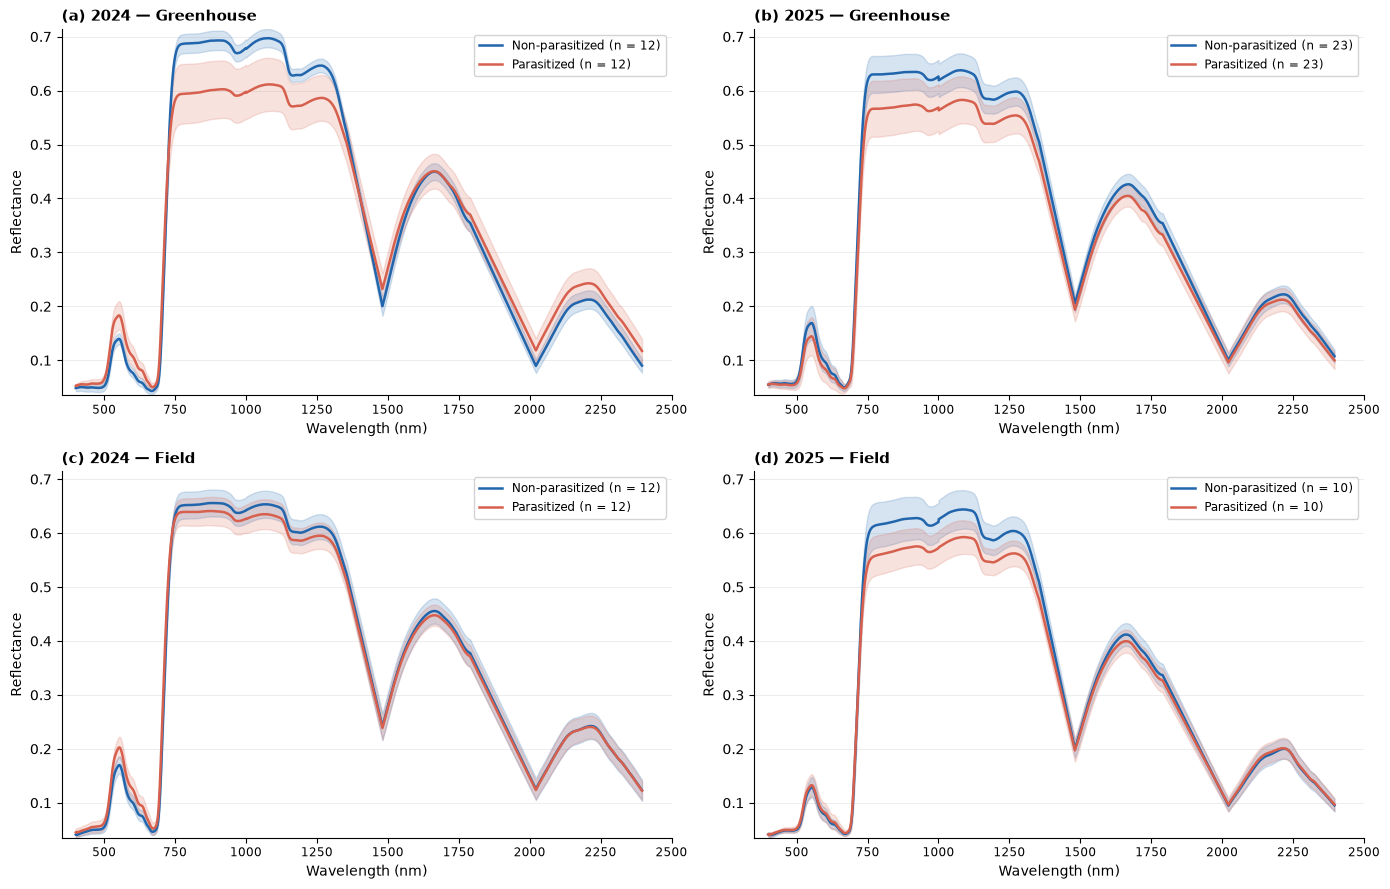

In [15]:
# Colours
C_HEALTHY = '#2166AC'      # blue: non-parasitized
C_PARASITIZED = '#D6604D'  # red-orange: parasitized

# Same y-axis range on all four panels (overall min/max of mean +/- SD)
y_lo = min((res['mean_healthy'] - res['std_healthy']).min() for res in results_for_figs)
y_hi = max((res['mean_para'] + res['std_para']).max() for res in results_for_figs)
y_hi = max(y_hi, max((res['mean_healthy'] + res['std_healthy']).max() for res in results_for_figs))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for ax, res, letter in zip(axes, results_for_figs, PANEL_LETTERS):
    wl = res['wl_clean']

    # Shaded band = mean +/- 1 SD; line = mean
    ax.fill_between(wl, res['mean_healthy'] - res['std_healthy'], res['mean_healthy'] + res['std_healthy'],
                    color=C_HEALTHY, alpha=0.18, zorder=2)
    ax.fill_between(wl, res['mean_para'] - res['std_para'], res['mean_para'] + res['std_para'],
                    color=C_PARASITIZED, alpha=0.18, zorder=2)
    ax.plot(wl, res['mean_healthy'], color=C_HEALTHY, lw=1.8, zorder=3,
            label=f"Non-parasitized (n = {int((res['labels']=='healthy').sum())})")
    ax.plot(wl, res['mean_para'], color=C_PARASITIZED, lw=1.8, zorder=3,
            label=f"Parasitized (n = {int((res['labels']=='parasitized').sum())})")

    # Axes and styling
    ax.set_title(f"{letter} {res['year']} \u2014 {res['location']}", fontsize=11, fontweight='bold', loc='left')
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Reflectance')
    ax.set_xlim(350, 2500)
    ax.set_ylim(y_lo, y_hi)
    xticks = list(range(500, 2501, 250))
    ax.set_xticks(xticks)
    ax.set_xticklabels([str(x) for x in xticks], fontsize=8.5, rotation=0, ha='center')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(fontsize=8.5, loc='upper right', framealpha=0.85)
    ax.grid(True, axis='y', alpha=0.2, lw=0.5, color='gray')

plt.tight_layout()
fig.savefig(f'{OUTPUT_DIR}/Figure1_spectral_signatures.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{OUTPUT_DIR}/Figure1_spectral_signatures.jpg', dpi=300, bbox_inches='tight')
plt.show()

## Section 6 — Figure 2: Absolute reflectance difference

Absolute difference between the mean reflectance of parasitized and
non-parasitized plants at each wavelength. The largest difference is labeled
in each panel.

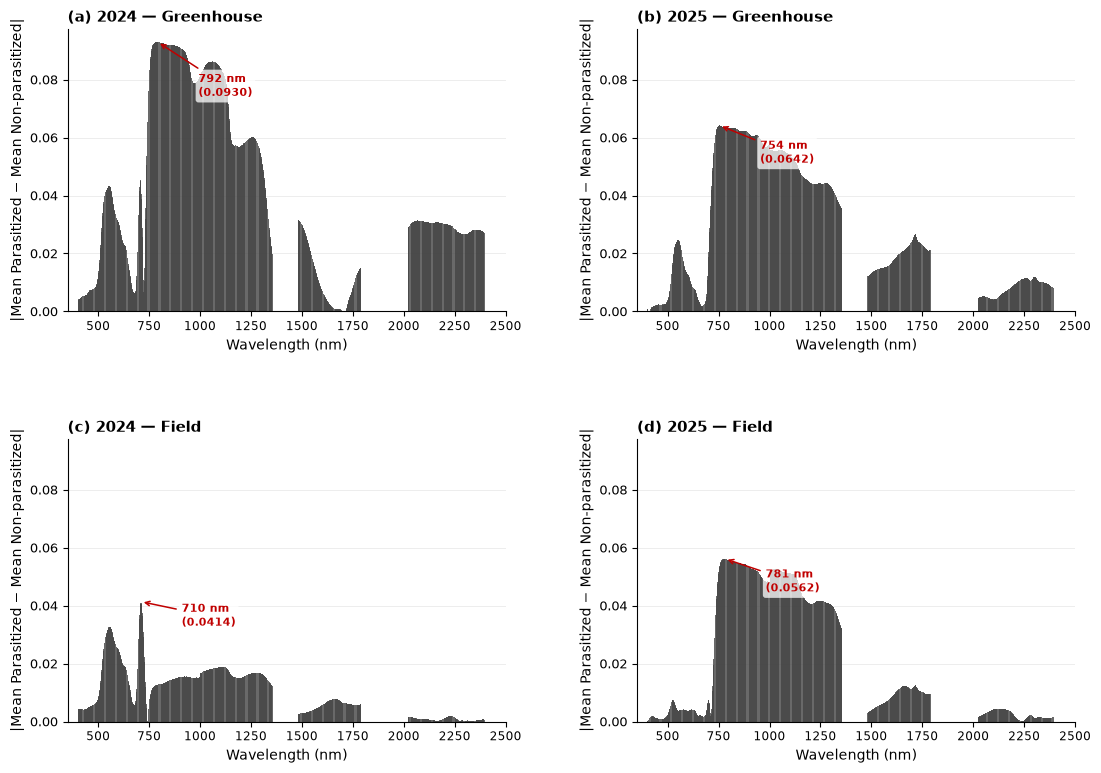

In [16]:
# Same y-axis range on all four panels
y_hi_diff = max(res['abs_diff'].max() for res in results_for_figs) * 1.05

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=False, sharey=False,
                         gridspec_kw={'hspace': 0.45, 'wspace': 0.30})
fig.patch.set_facecolor('white')

for i, (res, letter) in enumerate(zip(results_for_figs, PANEL_LETTERS)):
    row, col = divmod(i, 2)
    ax = axes[row, col]
    wl = res['wl_clean']
    diff = res['abs_diff']      # |mean parasitized - mean non-parasitized|

    ax.bar(wl, diff, width=1.8, color='#444444', alpha=0.80, zorder=2)

    # Label the wavelength with the largest difference
    # (label placed to the left if the peak is beyond 1800 nm, so it is not cut off)
    pk_idx = np.argmax(diff)
    pk_wl = wl[pk_idx]
    pk_val = diff[pk_idx]
    x_off = 200 if pk_wl < 1800 else -300
    ax.annotate(
        f'{pk_wl:.0f} nm\n({pk_val:.4f})',
        xy=(pk_wl, pk_val),
        xytext=(pk_wl + x_off, pk_val * 0.80),
        arrowprops=dict(arrowstyle='->', color='#C00000', lw=1.1),
        fontsize=8, color='#C00000', fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.25', fc='white', alpha=0.75, ec='none')
    )

    # Axes and styling
    ax.set_title(f"{letter} {res['year']} \u2014 {res['location']}",
                 fontsize=11, fontweight='bold', loc='left', pad=5)
    ax.set_ylabel('|Mean Parasitized \u2212 Mean Non-parasitized|', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(350, 2500)
    ax.set_ylim(0, y_hi_diff)
    xticks = list(range(500, 2501, 250))
    ax.set_xticks(xticks)
    ax.set_xticklabels([str(x) for x in xticks], fontsize=8.5, rotation=0, ha='center')
    ax.tick_params(axis='y', labelsize=9)
    ax.grid(True, axis='y', alpha=0.2, lw=0.5, color='gray')
    ax.set_xlabel('Wavelength (nm)', fontsize=10)

plt.savefig(f'{OUTPUT_DIR}/Figure2_absolute_difference.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig(f'{OUTPUT_DIR}/Figure2_absolute_difference.jpg', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## Section 7 — Table 3: PLS-DA model performance

Calibration and nested cross-validation performance of the raw-spectra and
first-derivative models for each dataset. "PLS factors" is the number of
components in the final model; "Components across outer folds" is the range
chosen in the nested cross-validation.

In [17]:
def build_summary_table(results_list):
    """One row per dataset and spectra type (raw, first derivative)."""
    rows = []
    for res in results_list:
        for spec_type, met in [('Raw spectra', res['met_raw']),
                               ('First Derivative', res['met_deriv'])]:
            rows.append({
                'Data': f"{res['year']} {res['location']}",
                'Spectra type': spec_type,
                # Number of components
                'PLS factors': met['n_components'],
                'Components across outer folds': f"{met['outer_n_comp_min']}-{met['outer_n_comp_max']}",
                # Calibration (final model, all plants)
                'R (cal)': round(met['r_cal'], 2),
                'RMSEC': round(met['rmsec'], 2),
                # Nested cross-validation
                'R (cv)': round(met['r_cv'], 2),
                'RMSEP': round(met['rmsep'], 2),
                'Prediction Accuracy %': round(met['accuracy'], 1),
                # Classification metrics (nested cross-validation)
                'Sensitivity': round(met['sensitivity'], 2),
                'Specificity': round(met['specificity'], 2),
                'Precision': round(met['precision'], 2),
                'F1 Score': round(met['f1_score'], 2),
                'ROC-AUC': round(met['roc_auc'], 2),
            })
    return pd.DataFrame(rows)


table3 = build_summary_table(results_in_order)
print("Table 3. PLS-DA results for parasitized vs. non-parasitized red clover.")
display(table3)
table3.to_excel(f'{OUTPUT_DIR}/Table3_PLS_summary.xlsx', index=False)

Table 3. PLS-DA results for parasitized vs. non-parasitized red clover.


,Data,Spectra type,PLS factors,Components across outer folds,R (cal),RMSEC,R (cv),RMSEP,Prediction Accuracy %,Sensitivity,Specificity,Precision,F1 Score,ROC-AUC
0,2024 Greenhouse,Raw spectra,10,4-10,0.99,0.05,0.87,0.26,95.8,0.92,1.00,1.00,0.96,1.00
1,2024 Greenhouse,First Derivative,3,3-8,0.99,0.06,0.95,0.15,100.0,1.00,1.00,1.00,1.00,1.00
2,2024 Field,Raw spectra,4,3-8,0.83,0.28,0.67,0.39,83.3,0.83,0.83,0.83,0.83,0.90
3,2024 Field,First Derivative,8,5-10,1.00,0.00,0.89,0.23,95.8,1.00,0.92,0.92,0.96,1.00
4,2025 Greenhouse,Raw spectra,6,5-10,0.82,0.28,0.65,0.41,80.4,0.74,0.87,0.85,0.79,0.89
5,2025 Greenhouse,First Derivative,4,4-10,0.96,0.14,0.85,0.27,91.3,0.91,0.91,0.91,0.91,0.99
6,2025 Field,Raw spectra,4,3-10,0.86,0.25,0.44,0.52,70.0,0.80,0.60,0.67,0.73,0.75
7,2025 Field,First Derivative,6,5-10,1.00,0.02,0.83,0.28,95.0,1.00,0.90,0.91,0.95,0.98


### Confusion matrices

Confusion matrices of the first-derivative models (nested leave-one-out
cross-validation). Panel titles give accuracy with its 95% exact binomial
confidence interval.

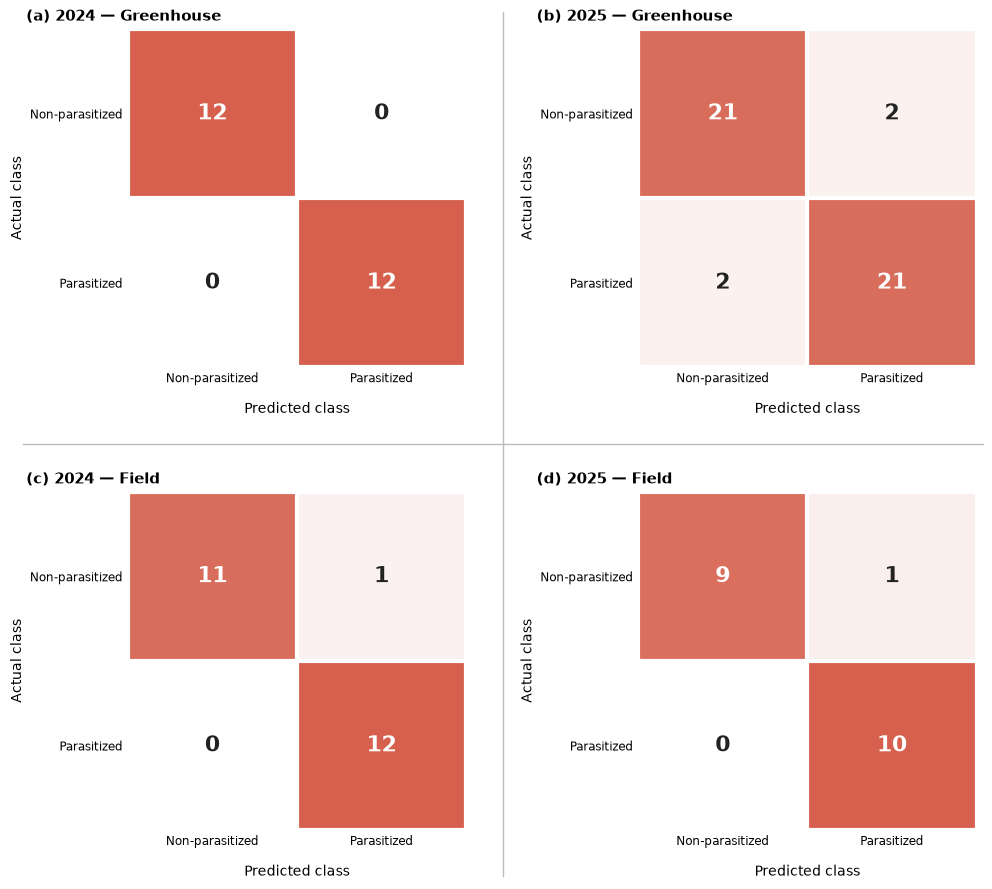

In [18]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

# Colour map: white -> the red-orange used for parasitized plants in Figure 1
CM_CMAP = LinearSegmentedColormap.from_list('cm_red', ['#FFFFFF', '#D6604D'])


def plot_confusion_matrices(results_list, met_key, out_name):
    """2x2 confusion matrices (rows = actual class, columns = predicted class)."""
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))      # same height as Figure 1; square cells
    axes = axes.ravel()
    class_names = ['Non-parasitized', 'Parasitized']

    for ax, res, letter in zip(axes, results_list, PANEL_LETTERS):
        met = res[met_key]

        # Counts from the nested CV predictions
        cm = np.array([[met['tn'], met['fp']],
                       [met['fn'], met['tp']]])
        row_prop = cm / cm.sum(axis=1, keepdims=True)   # shading: proportion of each actual class

        ax.imshow(row_prop, cmap=CM_CMAP, vmin=0, vmax=1, aspect='equal')

        # Number of plants in each cell
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]}", ha='center', va='center',
                        fontsize=16, fontweight='bold',
                        color='white' if row_prop[i, j] > 0.5 else '#222222')

        # Axes
        ax.set_xticks([0, 1])
        ax.set_xticklabels(class_names, fontsize=8.5)
        ax.set_yticks([0, 1])
        ax.set_yticklabels(class_names, fontsize=8.5)
        ax.set_xlabel('Predicted class', labelpad=12)
        ax.set_ylabel('Actual class')

        # White lines between cells, no frame
        ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
        ax.grid(which='minor', color='white', linewidth=3)
        ax.tick_params(which='both', length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

        # Title: same format as Figure 1
        ax.set_title(f"{letter} {res['year']} \u2014 {res['location']}",
                     fontsize=11, fontweight='bold', loc='left', x=-0.3)

    # Extra space between panels so labels do not touch the neighbouring matrix
    plt.tight_layout(w_pad=5, h_pad=4)

    # Grey divider lines between the four panels
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    to_fig = fig.transFigure.inverted()
    box = [to_fig.transform_bbox(ax.get_tightbbox(renderer)) for ax in axes]
    x_mid = (box[0].x1 + box[1].x0) / 2 + 0.01   # between left and right columns (shifted slightly right)
    y_mid = (box[2].y1 + box[0].y0) / 2          # between top and bottom rows
    fig.add_artist(Line2D([x_mid, x_mid], [0.02, 0.98], transform=fig.transFigure,
                          color='#BBBBBB', lw=1))
    fig.add_artist(Line2D([0.02, 0.98], [y_mid, y_mid], transform=fig.transFigure,
                          color='#BBBBBB', lw=1))

    fig.savefig(f'{OUTPUT_DIR}/{out_name}.jpg', dpi=300, bbox_inches='tight')
    plt.show()


# First-derivative models
plot_confusion_matrices(results_for_figs, 'met_deriv', 'FigureS_confusion_matrices_derivative')

### Uncertainty of classification performance

Accuracy, sensitivity and specificity with 95% exact binomial
(Clopper–Pearson) confidence intervals, calculated from the nested
leave-one-out predictions.

In [19]:
# 95% confidence intervals for accuracy, sensitivity and specificity (nested cross-validation)
ci_rows = []
for res in results_in_order:
    for spec_type, met in [('Raw spectra', res['met_raw']),
                           ('First Derivative', res['met_deriv'])]:
        tp, tn, fp, fn = met['tp'], met['tn'], met['fp'], met['fn']

        # 95% exact binomial confidence intervals
        acc_lo, acc_hi = exact_ci(tp + tn, tp + tn + fp + fn)   # all plants
        sens_lo, sens_hi = exact_ci(tp, tp + fn)                # parasitized plants
        spec_lo, spec_hi = exact_ci(tn, tn + fp)                # non-parasitized plants

        ci_rows.append({
            'Data': f"{res['year']} {res['location']}",
            'Spectra type': spec_type,
            'n': tp + tn + fp + fn,
            'Accuracy % (95% CI)': f"{met['accuracy']:.1f} ({acc_lo*100:.1f}-{acc_hi*100:.1f})",
            'Sensitivity (95% CI)': f"{met['sensitivity']:.2f} ({sens_lo:.2f}-{sens_hi:.2f})",
            'Specificity (95% CI)': f"{met['specificity']:.2f} ({spec_lo:.2f}-{spec_hi:.2f})",
        })

table_ci = pd.DataFrame(ci_rows)
print("Accuracy, sensitivity and specificity with 95% confidence intervals (nested leave-one-out cross-validation).")
display(table_ci)
table_ci.to_excel(f'{OUTPUT_DIR}/TableS2_classification_CI.xlsx', index=False)

Accuracy, sensitivity and specificity with 95% confidence intervals (nested leave-one-out cross-validation).


,Data,Spectra type,n,Accuracy % (95% CI),Sensitivity (95% CI),Specificity (95% CI)
0,2024 Greenhouse,Raw spectra,24,95.8 (78.9-99.9),0.92 (0.62-1.00),1.00 (0.74-1.00)
1,2024 Greenhouse,First Derivative,24,100.0 (85.8-100.0),1.00 (0.74-1.00),1.00 (0.74-1.00)
2,2024 Field,Raw spectra,24,83.3 (62.6-95.3),0.83 (0.52-0.98),0.83 (0.52-0.98)
3,2024 Field,First Derivative,24,95.8 (78.9-99.9),1.00 (0.74-1.00),0.92 (0.62-1.00)
4,2025 Greenhouse,Raw spectra,46,80.4 (66.1-90.6),0.74 (0.52-0.90),0.87 (0.66-0.97)
5,2025 Greenhouse,First Derivative,46,91.3 (79.2-97.6),0.91 (0.72-0.99),0.91 (0.72-0.99)
6,2025 Field,Raw spectra,20,70.0 (45.7-88.1),0.80 (0.44-0.97),0.60 (0.26-0.88)
7,2025 Field,First Derivative,20,95.0 (75.1-99.9),1.00 (0.69-1.00),0.90 (0.55-1.00)


## Section 8 — Cross-year validation

Tests whether a model trained on one year can classify plants from the other
year in the same environment (greenhouse 2024 ↔ 2025; field 2024 ↔ 2025).
The number of components is chosen from the training year only, and the
test year is never used for training.

In [20]:
def load_spectra(filepath):
    """
    Load one dataset and apply the same pre-processing as Section 4
    (noisy-band removal, first derivative).
    """
    df = pd.read_excel(filepath)
    meta_cols = ['sample_id', 'treatment', 'treatment_code']
    wl_cols = [c for c in df.columns if c not in meta_cols]
    wavelengths = np.array([float(w) for w in wl_cols])
    X_full = df[wl_cols].values.astype(float)
    y = df['treatment_code'].values.astype(float)   # 0 = non-parasitized, 1 = parasitized

    keep_mask = remove_noisy_bands(wavelengths, NOISY_RANGES)
    wl_clean = wavelengths[keep_mask]
    X_raw = X_full[:, keep_mask]
    X_deriv, wl_deriv = compute_first_derivative(X_raw, wl_clean)

    return {'X_raw': X_raw, 'wl_clean': wl_clean,
            'X_deriv': X_deriv, 'wl_deriv': wl_deriv, 'y': y}

In [21]:
def cross_year_validation(train, test, spectra_key, wl_key, max_components=10):
    """
    Train a PLS-DA model on one dataset and test it on another.

    1. Choose the number of components by LOO on the training dataset only.
    2. Fit the model on all training plants.
    3. Predict every plant in the test dataset.
    Scaling (scale=True) is learned from the training data only.
    """
    assert np.array_equal(train[wl_key], test[wl_key]), \
        "Wavelength grids differ between training and test datasets."

    X_train, y_train = train[spectra_key], train['y']
    X_test, y_test = test[spectra_key], test['y']

    n_comp = select_n_components_loo(X_train, y_train, max_components)
    model = PLSRegression(n_components=n_comp, scale=True)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test).ravel()
    rmsep = np.sqrt(mean_squared_error(y_test, y_pred))
    metrics = compute_classification_metrics(y_test, y_pred)

    return n_comp, rmsep, metrics, y_pred

In [22]:
# Pre-processed spectra for all four datasets
SPECTRA = {(d['year'], d['location']): load_spectra(d['filepath']) for d in DATASETS}

# (training dataset, test dataset)
CROSS_YEAR_PAIRS = [
    (("2024", "Greenhouse"), ("2025", "Greenhouse")),
    (("2025", "Greenhouse"), ("2024", "Greenhouse")),
    (("2024", "Field"),      ("2025", "Field")),
    (("2025", "Field"),      ("2024", "Field")),
]

rows = []
for train_key, test_key in CROSS_YEAR_PAIRS:
    for spec_type, spectra_key, wl_key in [('Raw spectra', 'X_raw', 'wl_clean'),
                                           ('First Derivative', 'X_deriv', 'wl_deriv')]:
        n_comp, rmsep, m, _ = cross_year_validation(
            SPECTRA[train_key], SPECTRA[test_key], spectra_key, wl_key, MAX_COMPONENTS)
        rows.append({
            'Train': f"{train_key[0]} {train_key[1]}",
            'Test': f"{test_key[0]} {test_key[1]}",
            'Spectra type': spec_type,
            'PLS factors (train)': n_comp,
            'RMSEP (test)': round(rmsep, 2),
            'Accuracy %': round(m['accuracy_check'], 1),
            'Sensitivity': round(m['sensitivity'], 2),
            'Specificity': round(m['specificity'], 2),
            'Precision': round(m['precision'], 2),
            'F1 Score': round(m['f1_score'], 2),
            'ROC-AUC': round(m['roc_auc'], 2),
            'TP': m['tp'], 'TN': m['tn'], 'FP': m['fp'], 'FN': m['fn'],
        })

table_cross_year = pd.DataFrame(rows)
print("Cross-year validation: model trained on one year, tested on the other year.")
display(table_cross_year)
table_cross_year.to_excel(f'{OUTPUT_DIR}/Table_cross_year_validation.xlsx', index=False)

Cross-year validation: model trained on one year, tested on the other year.


,Train,Test,Spectra type,PLS factors (train),RMSEP (test),Accuracy %,Sensitivity,Specificity,Precision,F1 Score,ROC-AUC,TP,TN,FP,FN
0,2024 Greenhouse,2025 Greenhouse,Raw spectra,10,0.73,50.0,0.52,0.48,0.50,0.51,0.40,12,11,12,11
1,2024 Greenhouse,2025 Greenhouse,First Derivative,3,0.67,43.5,0.65,0.22,0.45,0.54,0.47,15,5,18,8
2,2025 Greenhouse,2024 Greenhouse,Raw spectra,6,0.86,37.5,0.75,0.00,0.43,0.55,0.22,9,0,12,3
3,2025 Greenhouse,2024 Greenhouse,First Derivative,4,0.70,45.8,0.92,0.00,0.48,0.63,0.19,11,0,12,1
4,2024 Field,2025 Field,Raw spectra,4,1.09,50.0,0.00,1.00,0.00,0.00,0.75,0,10,0,10
5,2024 Field,2025 Field,First Derivative,8,0.76,50.0,0.00,1.00,0.00,0.00,0.60,0,10,0,10
6,2025 Field,2024 Field,Raw spectra,4,1.00,50.0,0.42,0.58,0.50,0.45,0.55,5,7,5,7
7,2025 Field,2024 Field,First Derivative,6,0.51,62.5,0.67,0.58,0.62,0.64,0.71,8,7,5,4


## Section 9 — Figure 3a: PLS-DA score plots, raw spectra

Scores of each plant on the first two latent variables (LV1, LV2) of the final
raw-spectra model. Axis labels give the % of spectral (X) variance explained
by each latent variable.

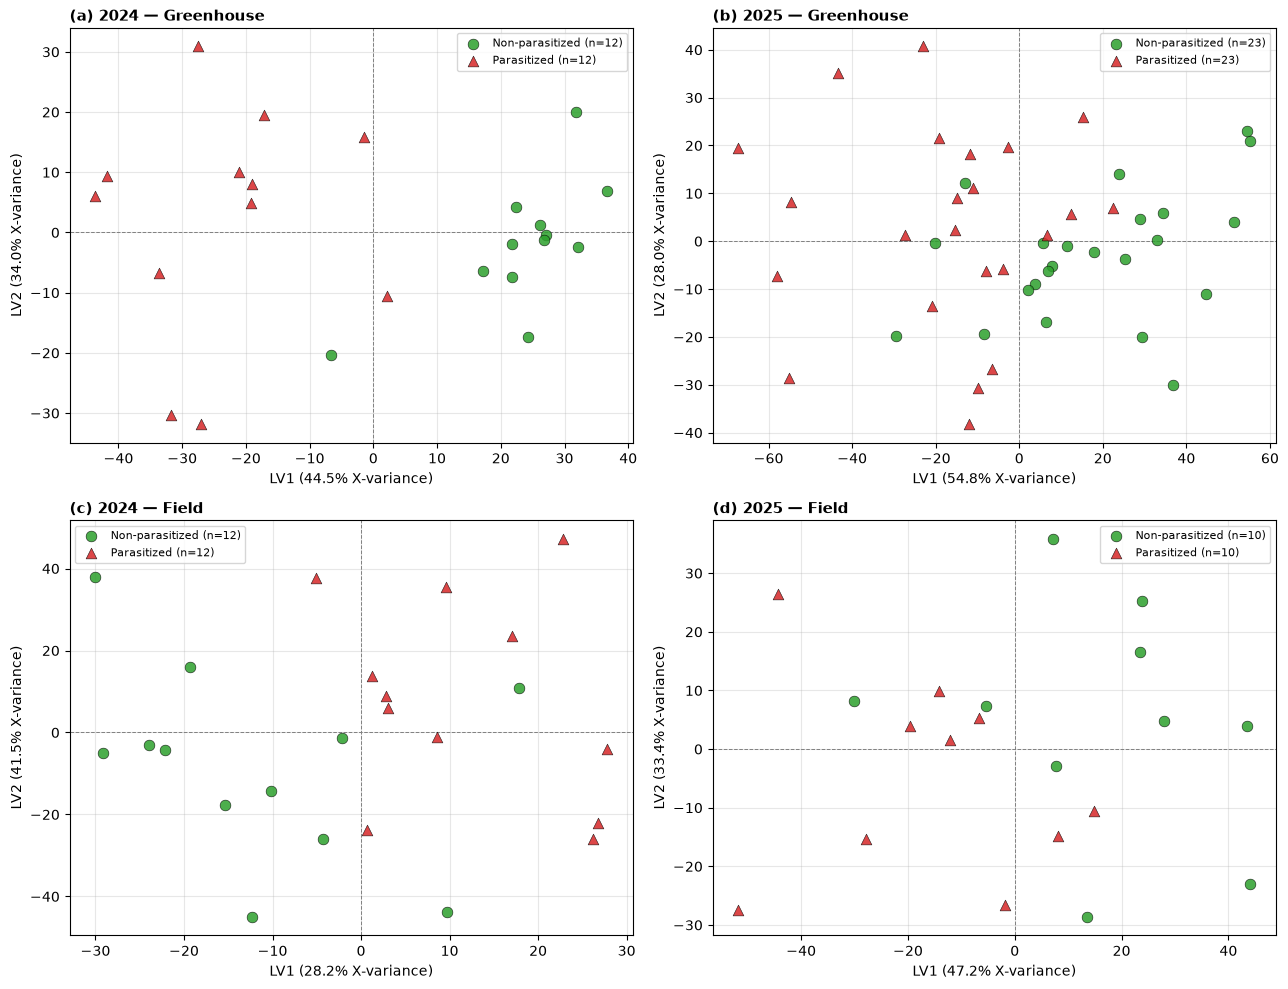

In [23]:
def plot_score_plots(results_list, model_key, met_key, title_prefix, out_name):
    """2x2 score plots (LV1 vs LV2) of the final PLS-DA model for each dataset."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    axes = axes.ravel()

    for i, (res, letter) in enumerate(zip(results_list, PANEL_LETTERS)):
        ax = axes[i]
        pls_model = res[model_key]
        labels = res['labels']

        # Scores of each plant on LV1 and LV2
        T = pls_model.x_scores_        # X-scores   (plants x components)
        P = pls_model.x_loadings_      # X-loadings (wavelengths x components)
        lv1 = T[:, 0]
        lv2 = T[:, 1] if pls_model.n_components > 1 else np.zeros(len(T))

        # % of X-variance explained by each latent variable.
        # X is scaled to unit variance inside the model, so the total sum of
        # squares of X is (n_plants - 1) x n_wavelengths.
        n, p = T.shape[0], P.shape[0]
        x_var = (T ** 2).sum(axis=0) * (P ** 2).sum(axis=0) / ((n - 1) * p) * 100
        lv1_exp = x_var[0]
        lv2_exp = x_var[1] if pls_model.n_components > 1 else 0

        # Plot each class
        for class_label, colour, marker in [('healthy', '#2ca02c', 'o'),
                                            ('parasitized', '#d62728', '^')]:
            idx = labels == class_label
            ax.scatter(lv1[idx], lv2[idx], c=colour, marker=marker, s=60,
                       edgecolors='k', linewidths=0.4,
                       label=f'{"Non-parasitized" if class_label=="healthy" else "Parasitized"} (n={idx.sum()})',
                       alpha=0.85, zorder=3)

        # Axes and styling
        ax.axhline(0, color='grey', lw=0.7, ls='--')
        ax.axvline(0, color='grey', lw=0.7, ls='--')
        ax.set_xlabel(f'LV1 ({lv1_exp:.1f}% X-variance)')
        ax.set_ylabel(f'LV2 ({lv2_exp:.1f}% X-variance)')
        ax.set_title(f"{letter} {res['year']} \u2014 {res['location']}",
                     fontsize=11, fontweight='bold', loc='left', pad=5)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig(f'{OUTPUT_DIR}/{out_name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(f'{OUTPUT_DIR}/{out_name}.jpg', dpi=300, bbox_inches='tight')
    plt.show()


plot_score_plots(results_for_figs, 'pls_raw', 'met_raw',
                 'PLS-DA Score Plots - Raw Spectra', 'Figure3a_score_plots_raw')

## Section 10 — Figure 3b: PLS-DA score plots, first derivative

Same as Figure 3a, for the first-derivative models (Figure 3 in the manuscript).

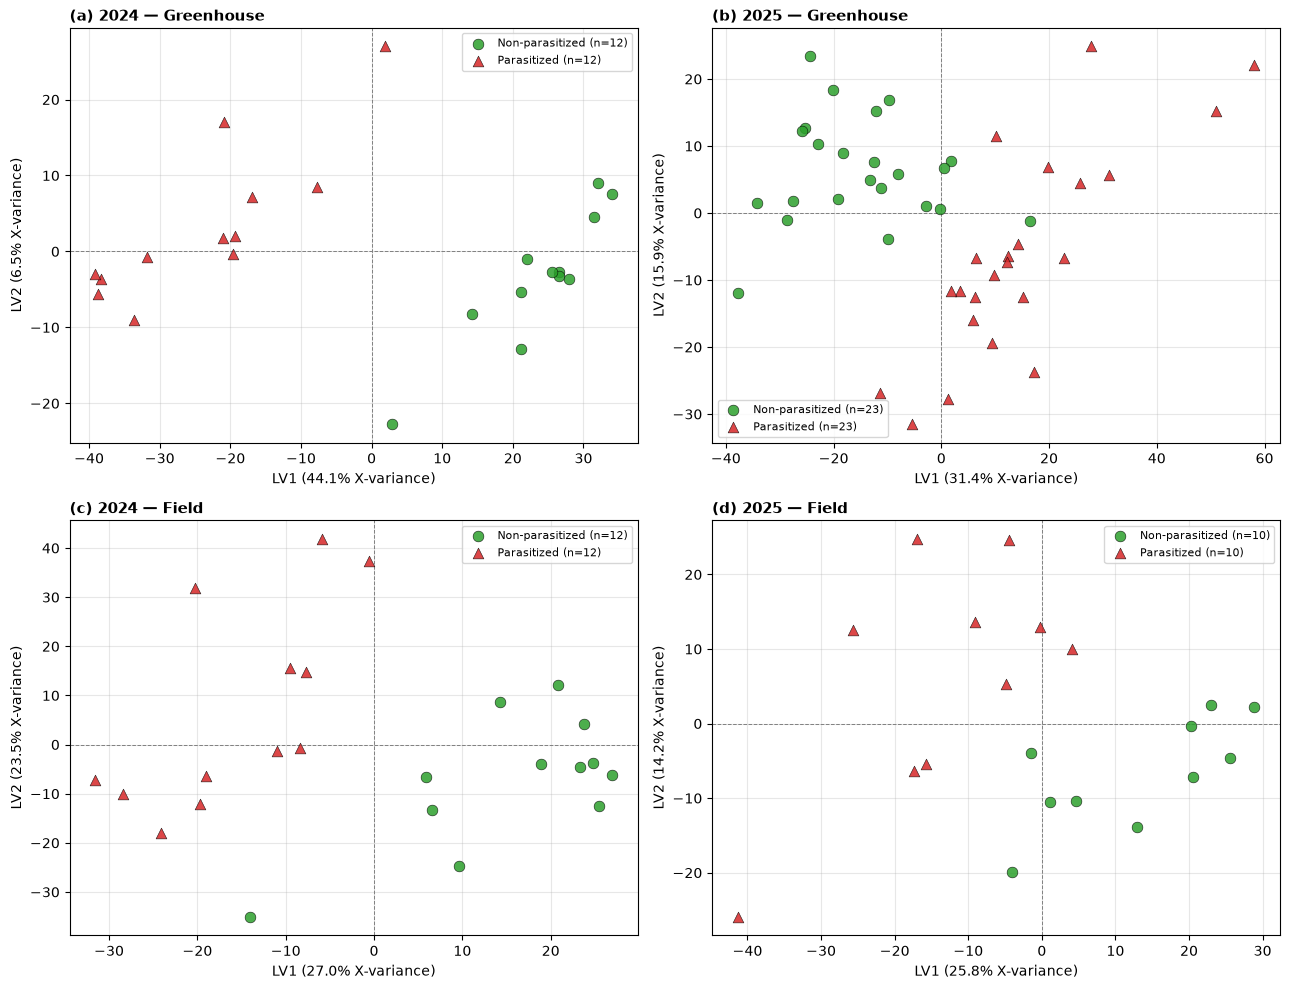

In [24]:
plot_score_plots(results_for_figs, 'pls_deriv', 'met_deriv',
                 'PLS-DA Score Plots - First Derivative', 'Figure3b_score_plots_derivative')

## Section 11 — Selected wavelengths (VIP)

**Consistency criterion (used for all VIP tables below):** a wavelength is
*selected* if VIP > 1 in **all four** datasets.

In [25]:
def consistently_selected(vip_arrays, threshold=1.0):
    """
    Consistency criterion: True for wavelengths with VIP > threshold in
    EVERY dataset in vip_arrays. Used by all VIP tables in this section.
    """
    return np.all([np.asarray(v) > threshold for v in vip_arrays], axis=0)

In [27]:
def common_vip_regions(results_list, vip_key, wl_key, threshold=1.0, gap_nm=1):
    """
    Table 4: wavelengths selected by the consistency criterion, grouped into
    bands of consecutive wavelengths. For each band, the mean VIP of its
    selected wavelengths is given for each dataset (descriptive only).
    """
    # All datasets share the same wavelength grid
    wl = results_list[0][wl_key]
    for res in results_list:
        assert np.array_equal(res[wl_key], wl), "Wavelength grids differ between datasets."

    # Apply the consistency criterion and group into bands
    vip_arrays = [res[vip_key] for res in results_list]
    selected = consistently_selected(vip_arrays, threshold)
    bands = group_wavelengths_into_ranges(wl[selected], gap_nm=gap_nm)

    rows = []
    for i, (start, end) in enumerate(bands, start=1):
        in_band = selected & (wl >= start) & (wl <= end)
        mean_vip = {f"{res['year']} {res['location']}": vip[in_band].mean()
                    for res, vip in zip(results_list, vip_arrays)}
        rows.append({
            'Region ID': i,
            'Wavelength (nm)': f'{start:.0f}' if start == end else f'{start:.0f}-{end:.0f}',
            'Spectral region': spectral_region_name((start + end) / 2),
            **{name: round(float(v), 3) for name, v in mean_vip.items()},
            'Overall mean VIP': round(float(np.mean(list(mean_vip.values()))), 3),
        })
    return pd.DataFrame(rows)


# Raw spectra
vip1_raw_table = common_vip_regions(results_in_order, vip_key='vip_raw', wl_key='wl_clean')
print("Selected wavelengths (VIP > 1 in all four datasets) - RAW SPECTRA")
display(vip1_raw_table)
vip1_raw_table.to_excel(f'{OUTPUT_DIR}/Table4_VIP_gt1_raw_spectra.xlsx', index=False)

# First derivative (Table 4 in the manuscript)
vip1_deriv_table = common_vip_regions(results_in_order, vip_key='vip_deriv', wl_key='wl_deriv')
print("\nSelected wavelengths (VIP > 1 in all four datasets) - FIRST DERIVATIVE")
display(vip1_deriv_table)
vip1_deriv_table.to_excel(f'{OUTPUT_DIR}/Table4_VIP_gt1_first_derivative.xlsx', index=False)

Selected wavelengths (VIP > 1 in all four datasets) - RAW SPECTRA


,Region ID,Wavelength (nm),Spectral region,2024 Greenhouse,2024 Field,2025 Greenhouse,2025 Field,Overall mean VIP
0,1,440-459,VIS,1.029,1.226,1.195,1.276,1.182
1,2,519-642,VIS,1.202,1.797,1.080,1.358,1.359
2,3,656-657,VIS,1.129,1.376,1.002,1.079,1.147
3,4,659-661,VIS,1.133,1.339,1.012,1.051,1.134
4,5,689-722,Red-edge,1.259,2.008,1.298,1.537,1.525
5,6,1053-1144,NIR,1.162,1.027,1.020,1.097,1.076
6,7,1242-1311,NIR,1.056,1.016,1.035,1.130,1.059



Selected wavelengths (VIP > 1 in all four datasets) - FIRST DERIVATIVE


,Region ID,Wavelength (nm),Spectral region,2024 Greenhouse,2024 Field,2025 Greenhouse,2025 Field,Overall mean VIP
0,1,485,VIS,1.144,1.068,1.061,1.333,1.152
1,2,632,VIS,1.095,1.046,1.062,1.280,1.121
2,3,634-635,VIS,1.122,1.440,1.002,1.082,1.162
3,4,713-718,Red-edge,1.299,1.375,1.110,1.256,1.260
4,5,766,NIR,1.453,1.434,1.150,1.026,1.266
5,6,799,NIR,1.084,1.328,1.249,1.216,1.219
6,7,849,NIR,1.354,1.035,1.188,1.024,1.150
7,8,851,NIR,1.082,1.301,1.175,1.221,1.195
8,9,887,NIR,1.105,1.143,1.070,1.318,1.159
9,10,894,NIR,1.306,1.594,1.323,1.962,1.546


### Table S1: individual selected wavelengths

Lists each selected wavelength (first-derivative models) with its VIP score
in each dataset, and summarizes the number of selected wavelengths in each
spectral region.

In [28]:
# Dataset names and the shared derivative wavelength grid
DATASET_NAMES = [f"{k[0]} {k[1]}" for k in PANEL_ORDER]
WL_DERIV = results_in_order[0]['wl_deriv']
for res in results_in_order:
    assert np.array_equal(res['wl_deriv'], WL_DERIV), "Wavelength grids differ between datasets."

# Apply the consistency criterion to the first-derivative VIP scores
VIP_DERIV = [res['vip_deriv'] for res in results_in_order]
sel = consistently_selected(VIP_DERIV, threshold=1.0)

# Table S1: one row per selected wavelength, VIP score in each dataset
table_s1 = pd.DataFrame({
    'Wavelength (nm)': WL_DERIV[sel].astype(int),
    'Spectral region': [spectral_region_name(w) for w in WL_DERIV[sel]],
})
for name, vip in zip(DATASET_NAMES, VIP_DERIV):
    table_s1[f'VIP {name}'] = np.round(vip[sel], 3)

# Region summary: number of selected wavelengths per region, and as a % of
# the wavelengths available in that region (regions differ in width)
region_rows = []
for lo, hi, region in SPECTRAL_REGIONS:
    in_region = (WL_DERIV >= lo) & (WL_DERIV < hi)
    n_available = int(in_region.sum())
    if n_available == 0:
        continue
    n_selected = int((sel & in_region).sum())
    region_rows.append({
        'Spectral region': region,
        'Wavelengths available': n_available,
        'Selected (VIP > 1 in all 4)': n_selected,
        '% of region selected': round(100 * n_selected / n_available, 1),
    })
region_summary = pd.DataFrame(region_rows)

print(f"Selected wavelengths (VIP > 1 in all four datasets): {sel.sum()}")
print(f"Number of bands: {len(group_wavelengths_into_ranges(WL_DERIV[sel], gap_nm=1))}")
display(region_summary)
display(table_s1)

region_summary.to_excel(f'{OUTPUT_DIR}/Table_VIP_region_summary.xlsx', index=False)
table_s1.to_excel(f'{OUTPUT_DIR}/TableS1_selected_wavelengths.xlsx', index=False)

Selected wavelengths (VIP > 1 in all four datasets): 47
Number of bands: 35


,Spectral region,Wavelengths available,Selected (VIP > 1 in all 4),% of region selected
0,VIS,300,4,1.3
1,Red-edge,30,6,20.0
2,NIR,570,19,3.3
3,SWIR-1,364,14,3.8
4,SWIR-2,374,4,1.1


,Wavelength (nm),Spectral region,VIP 2024 Greenhouse,VIP 2024 Field,VIP 2025 Greenhouse,VIP 2025 Field
0,485,VIS,1.144,1.068,1.061,1.333
1,632,VIS,1.095,1.046,1.062,1.280
2,634,VIS,1.099,1.389,1.003,1.128
3,635,VIS,1.144,1.492,1.001,1.037
4,713,Red-edge,1.213,1.101,1.196,1.208
5,714,Red-edge,1.264,1.276,1.153,1.244
6,715,Red-edge,1.301,1.395,1.126,1.261
7,716,Red-edge,1.321,1.433,1.118,1.266
8,717,Red-edge,1.338,1.493,1.060,1.279
9,718,Red-edge,1.354,1.554,1.009,1.279


### Reduced model using selected wavelengths

Tests whether a model using only selected wavelengths still classifies
accurately. For each dataset, wavelengths are selected from the **other three**
datasets (VIP > 1 in all three), so the tested dataset is not used to choose
them. The reduced model is evaluated with the same nested LOO
cross-validation as the full-spectrum model (Table 3).

In [29]:
def reduced_model_leave_one_dataset_out(test_key, threshold=1.0):
    """
    Reduced PLS-DA model for one dataset (test_key):
      1. Select wavelengths with VIP > threshold in all of the OTHER three datasets.
      2. Fit a model on test_key using only those wavelengths, evaluated with
         nested LOO cross-validation.
    Returns the selected-wavelength mask, model metrics and classification metrics.
    """
    other_keys = [k for k in PANEL_ORDER if k != test_key]
    band_mask = consistently_selected([all_results[k]['vip_deriv'] for k in other_keys],
                                      threshold=threshold)
    if band_mask.sum() == 0:
        return band_mask, None, None

    X = SPECTRA[test_key]['X_deriv'][:, band_mask]
    y = SPECTRA[test_key]['y']
    _, met, _, y_cv_pred = fit_pls_with_nested_cv(X, y, MAX_COMPONENTS)
    class_met = compute_classification_metrics(y, y_cv_pred)
    return band_mask, met, class_met

In [30]:
# Reduced vs full-spectrum performance for each dataset.
# Full-spectrum values are the first-derivative results in Table 3
# (same nested LOO cross-validation).
reduced_rows = []
for key, name in zip(PANEL_ORDER, DATASET_NAMES):
    band_mask, met, cm = reduced_model_leave_one_dataset_out(key, threshold=1.0)
    full = all_results[key]['met_deriv']
    if met is None:
        print(f"{name}: no wavelengths selected from the other three datasets; skipped.")
        continue
    reduced_rows.append({
        'Test dataset': name,
        'Wavelengths used (selected from other 3)': int(band_mask.sum()),
        'PLS factors': met['n_components'],
        'Components across outer folds': f"{met['outer_n_comp_min']}-{met['outer_n_comp_max']}",
        'Reduced accuracy %': round(met['accuracy'], 1),
        'Reduced ROC-AUC': round(cm['roc_auc'], 2),
        'Reduced sensitivity': round(cm['sensitivity'], 2),
        'Reduced specificity': round(cm['specificity'], 2),
        'Full-spectrum accuracy %': round(full['accuracy'], 1),
        'Full-spectrum ROC-AUC': round(full['roc_auc'], 2),
    })

table_reduced = pd.DataFrame(reduced_rows)
print("Reduced model (selected wavelengths only) vs full spectrum, nested LOO CV")
display(table_reduced)
table_reduced.to_excel(f'{OUTPUT_DIR}/Table_reduced_model_validation.xlsx', index=False)

Reduced model (selected wavelengths only) vs full spectrum, nested LOO CV


,Test dataset,Wavelengths used (selected from other 3),PLS factors,Components across outer folds,Reduced accuracy %,Reduced ROC-AUC,Reduced sensitivity,Reduced specificity,Full-spectrum accuracy %,Full-spectrum ROC-AUC
0,2024 Greenhouse,106,6,3-6,100.0,1.00,1.00,1.00,100.0,1.00
1,2024 Field,189,5,3-5,91.7,0.99,0.92,0.92,95.8,1.00
2,2025 Greenhouse,120,4,3-9,89.1,0.95,0.87,0.91,91.3,0.99
3,2025 Field,176,9,5-10,95.0,1.00,1.00,0.90,95.0,0.98
